# Phase 10: Portfolio Backtesting Engine

**Project:** Machine-Learning-Based Sector Rotation Regime Discovery in the Indian Equity Market  
**Phase:** 10  
**Authoritative Inputs:**  
- Four Target-Weight Schedules: `results/portfolio_construction/target_weights_{1A,1B,2A,2B}.csv` (1,687 sessions each)
- Aligned Historical Closing Prices: `data/processed/aligned/` (`nifty_{auto,bank,fmcg,it,metal,pharma,50}_aligned.csv`)
- Causal Hidden Markov Model Probabilities: `results/regime_discovery/hmm_causal_probabilities.csv`
- Methodology Review & Validation: `reports/phase10_2_methodology_review.md`
- Portfolio Backtest Module: `src/portfolio_backtest.py`

---

### Scope and Frozen Strategy Specifications
1. **Four Strategy Variants:**
   - **Variant 1A:** Template A (100% equity, 0% cash), Equal-Weighted Top-2 candidate sectors.
   - **Variant 1B:** Template A (100% equity, 0% cash), 20-day Inverse-Volatility-Weighted Top-2 candidate sectors.
   - **Variant 2A:** Template B (Defensive cash floor: R0/R2/R4: 0%, R1: 30%, R3: 40%, R5: 20%), Equal-Weighted.
   - **Variant 2B:** Template B (Defensive cash floor), 20-day Inverse-Volatility-Weighted.
2. **Operational Rules:**
   - **Next-Session Close ($t+1$ Close) Execution:** Signals generated at Day $t$ Close execute at Day $t+1$ Close with zero look-ahead bias.
   - **Dynamic Weight Drift:** Portfolio weights drift continuously between rebalances under asset price returns.
   - **Actual One-Way Turnover:** Rebalance costs computed strictly on actual one-way turnover against pre-trade drifted weights: $TO_{\text{actual}} = \frac{1}{2} \sum |w^{\text{target}} - \tilde{w}|$.
   - **Dual Accounting:** Gross simulation (0 bps) and Net simulation (15 bps one-way fee).
   - **Day 0 / Day 1 Funding Sequence:** Day 0 (2019-10-31) initialized with 100% NIFTY 50 (NAV = 1.0); Day 1 earns NIFTY 50 return and transitions to target at Day 1 Close (100% turnover fee).
   - **Continuous Train-to-Holdout Boundary:** Seamless preservation of holdings and NAV across the `2024-12-31` to `2025-01-02` boundary with zero reset.
   - **Exact Attribution Identity:** $R_{\text{net}} = \sum C_i + C_{\text{cost}}$ holds with machine precision every session.
   - **Parquet Storage:** Authoritative daily records persisted in Apache Parquet format.

## 1. Environment Setup and Imports

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import Phase 10.3 portfolio backtesting functions and constants
from src.portfolio_backtest import (
    ALL_ASSETS,
    SECTOR_NAMES,
    VARIANTS,
    DEFAULT_TRANSACTION_COST_RATE,
    EXPECTED_TOTAL_RETURN_INTERVALS,
    EXPECTED_TRAIN_RETURN_INTERVALS,
    EXPECTED_HOLDOUT_RETURN_INTERVALS,
    calculate_drifted_weights,
    calculate_actual_turnover,
    load_backtest_inputs,
    simulate_portfolio,
    run_all_simulations,
    compute_metrics,
    compute_attribution,
    generate_metrics_table,
    save_simulation_parquet,
    reload_and_verify_parquet,
    run_portfolio_backtest_pipeline,
)

print(f"Environment initialized successfully.")
print(f"Project root: {project_root}")

Environment initialized successfully.
Project root: c:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery


## 2. Input Data Validation and Verification

Verify that the four target-weight schedules, aligned sector closing prices, and causal probabilities exist, have identical dates (1,687 sessions covering 2019-10-31 to 2026-09-18), and contain zero missing values.

In [2]:
schedules, price_df, prob_df = load_backtest_inputs()

print(f"Successfully loaded backtest inputs:")
print(f"- Price DataFrame sessions: {len(price_df)} ({price_df.index.min().date()} to {price_df.index.max().date()})")
print(f"- Causal Probability sessions: {len(prob_df)} ({prob_df.index.min().date()} to {prob_df.index.max().date()})")
for v in VARIANTS:
    print(f"- Schedule {v}: {len(schedules[v])} dates, {schedules[v]['rebalance_triggered'].sum()} rebalances authorized")

# Verify date alignment
for v in VARIANTS:
    assert set(schedules[v].index).issubset(set(price_df.index)), f"Schedule {v} missing in prices"
    assert (schedules[v].index == prob_df.index).all(), f"Schedule {v} prob mismatch"
print("All 1,687 simulation dates are 100% calendar-synchronized across all input datasets.")

Successfully loaded backtest inputs:
- Price DataFrame sessions: 1886 (2019-01-02 to 2026-09-18)
- Causal Probability sessions: 1687 (2019-10-31 to 2026-09-18)
- Schedule 1A: 1687 dates, 58 rebalances authorized
- Schedule 1B: 1687 dates, 58 rebalances authorized
- Schedule 2A: 1687 dates, 58 rebalances authorized
- Schedule 2B: 1687 dates, 58 rebalances authorized
All 1,687 simulation dates are 100% calendar-synchronized across all input datasets.


## 3. Daily Asset and Benchmark Return Preparation

The backtesting engine evaluates simple daily returns: $r_{i, t} = \frac{P_{i, t}}{P_{i, t-1}} - 1$.  
With 1,687 daily price observations, there are exactly $N = 1,686$ return intervals:  
- **Training Period:** 1,265 price observations (`2019-10-31` to `2024-12-31`) $\rightarrow$ **1,264 return intervals**
- **Holdout Period:** 422 price observations (`2025-01-02` to `2026-09-18`) $\rightarrow$ **422 return intervals**  
- **Boundary Assignment:** The return from `2024-12-31` Close to `2025-01-02` Close represents the first holding return of the holdout period ($t=1,265$).

In [3]:
sim_dates = schedules["1A"].index
price_sim = price_df.loc[sim_dates]
daily_returns = price_sim.pct_change().dropna()
daily_returns["CASH"] = 0.0

n_total = len(daily_returns)
train_rets = daily_returns.loc["2019-11-01":"2024-12-31"]
holdout_rets = daily_returns.loc["2025-01-02":"2026-09-18"]

print(f"Daily Return Intervals Summary:")
print(f"- Total return intervals: {n_total} (Expected: {EXPECTED_TOTAL_RETURN_INTERVALS})")
print(f"- Training intervals: {len(train_rets)} (Expected: {EXPECTED_TRAIN_RETURN_INTERVALS})")
print(f"- Holdout intervals: {len(holdout_rets)} (Expected: {EXPECTED_HOLDOUT_RETURN_INTERVALS})")
assert n_total == EXPECTED_TOTAL_RETURN_INTERVALS
assert len(train_rets) == EXPECTED_TRAIN_RETURN_INTERVALS
assert len(holdout_rets) == EXPECTED_HOLDOUT_RETURN_INTERVALS
print("Exact return interval count reconciliation verified.")

Daily Return Intervals Summary:
- Total return intervals: 1686 (Expected: 1686)
- Training intervals: 1264 (Expected: 1264)
- Holdout intervals: 422 (Expected: 422)
Exact return interval count reconciliation verified.


## 4. Four-Variant Simulation Execution

Execute the simulation for variants 1A, 1B, 2A, and 2B across all 1,686 return intervals.  
Every session models:
1. Holdings earned over previous close to current close.
2. Natural price drift: $\tilde{w}_{i, t} = \frac{w_{i, t-1} (1 + r_{i, t})}{\sum_j w_{j, t-1} (1 + r_{j, t})}$.
3. Execution of rebalances authorized on previous day: transaction cost $TC = NAV_{\text{pre}} \times TO_{\text{actual}} \times 0.0015$.
4. Exact return attribution: $R_{\text{net}} = \sum C_i + C_{\text{cost}}$.

In [4]:
simulations = run_all_simulations(
    schedules=schedules,
    price_df=price_df,
    prob_df=prob_df,
    cost_rate=DEFAULT_TRANSACTION_COST_RATE,
)

for v, df in simulations.items():
    print(f"Variant {v} Simulation:")
    print(f"  - Intervals: {len(df)}")
    print(f"  - Rebalances executed: {df['rebalance_executed'].sum()}")
    print(f"  - Cumulative actual turnover: {df['actual_turnover'].sum():.4f}")
    print(f"  - Cumulative transaction costs: {df['transaction_cost'].sum():.4f}")
    print(f"  - Final Gross NAV: {df['gross_nav'].iloc[-1]:.4f}")
    print(f"  - Final Net NAV: {df['net_nav'].iloc[-1]:.4f}")

Variant 1A Simulation:
  - Intervals: 1686
  - Rebalances executed: 58
  - Cumulative actual turnover: 50.5609
  - Cumulative transaction costs: 0.3182
  - Final Gross NAV: 5.3089
  - Final Net NAV: 4.9209
Variant 1B Simulation:
  - Intervals: 1686
  - Rebalances executed: 58
  - Cumulative actual turnover: 51.6063
  - Cumulative transaction costs: 0.3172
  - Final Gross NAV: 5.2387
  - Final Net NAV: 4.8482
Variant 2A Simulation:
  - Intervals: 1686
  - Rebalances executed: 58
  - Cumulative actual turnover: 51.2326
  - Cumulative transaction costs: 0.2829
  - Final Gross NAV: 4.5794
  - Final Net NAV: 4.2405
Variant 2B Simulation:
  - Intervals: 1686
  - Rebalances executed: 58
  - Cumulative actual turnover: 52.1028
  - Cumulative transaction costs: 0.2788
  - Final Gross NAV: 4.4731
  - Final Net NAV: 4.1366


## 5. Gross vs Net Equity Curve Analysis and Drawdowns

Compare gross and net equity curves for each strategy variant and inspect historical drawdowns.

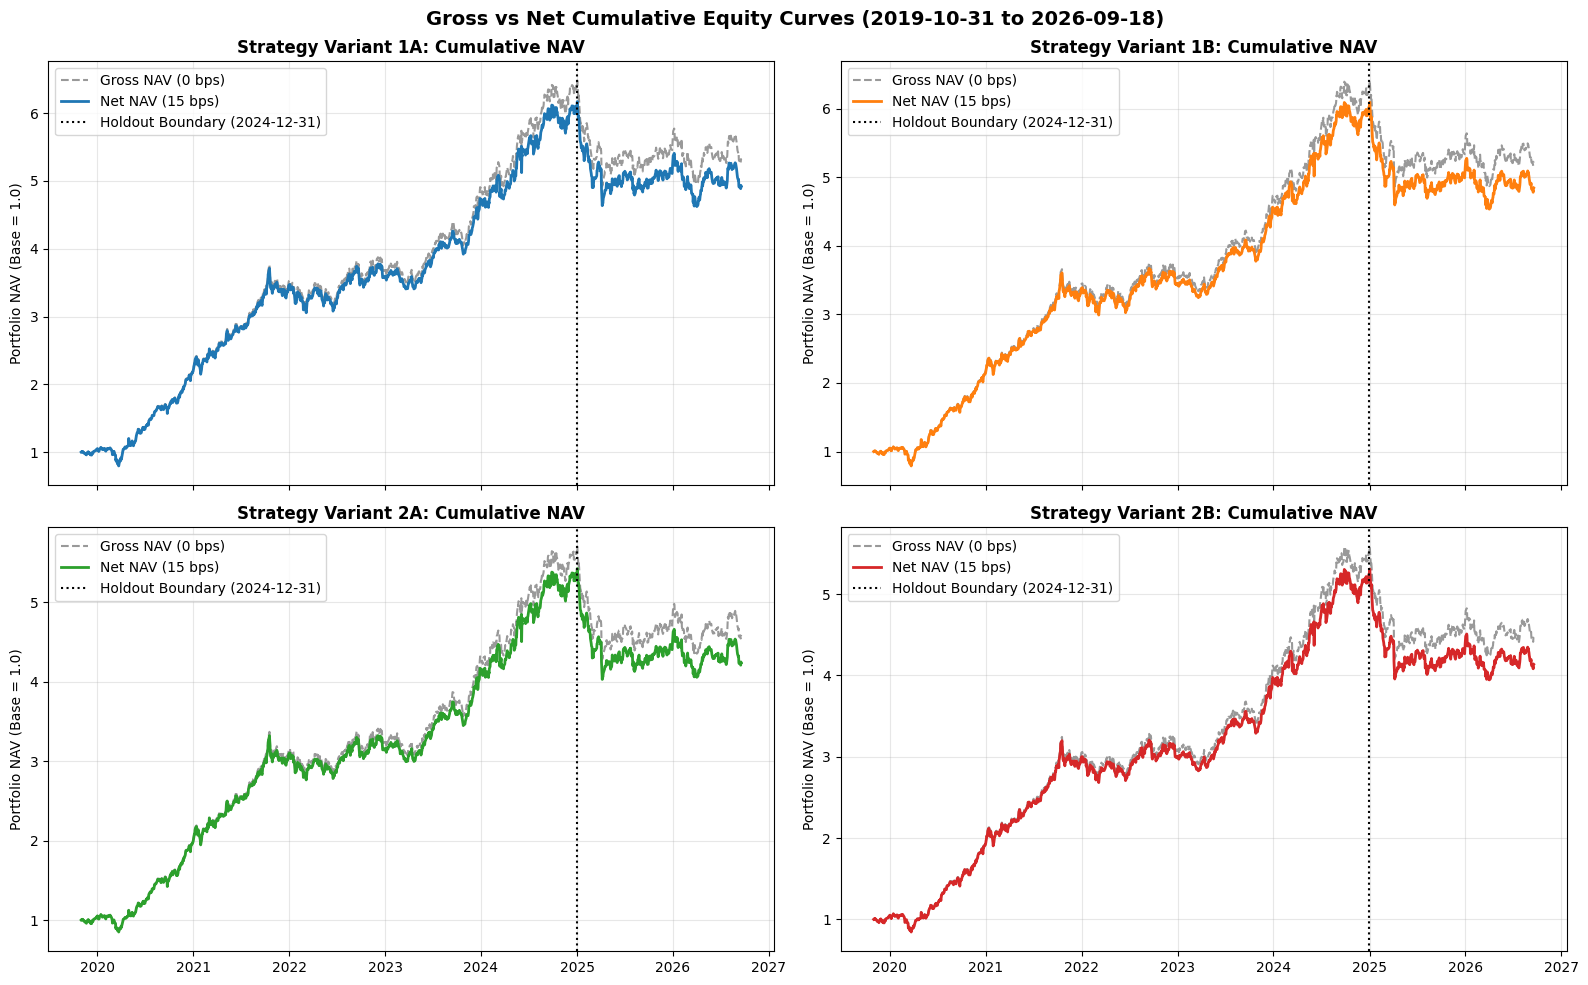

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
axes = axes.flatten()

colors = {"1A": "#1f77b4", "1B": "#ff7f0e", "2A": "#2ca02c", "2B": "#d62728"}

for idx, v in enumerate(VARIANTS):
    ax = axes[idx]
    df = simulations[v]
    ax.plot(df.index, df["gross_nav"], label="Gross NAV (0 bps)", color="gray", linestyle="--", alpha=0.8)
    ax.plot(df.index, df["net_nav"], label="Net NAV (15 bps)", color=colors[v], linewidth=2.0)
    ax.axvline(pd.Timestamp("2024-12-31"), color="black", linestyle=":", label="Holdout Boundary (2024-12-31)")
    ax.set_title(f"Strategy Variant {v}: Cumulative NAV", fontsize=12, fontweight="bold")
    ax.set_ylabel("Portfolio NAV (Base = 1.0)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", frameon=True)

plt.suptitle("Gross vs Net Cumulative Equity Curves (2019-10-31 to 2026-09-18)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

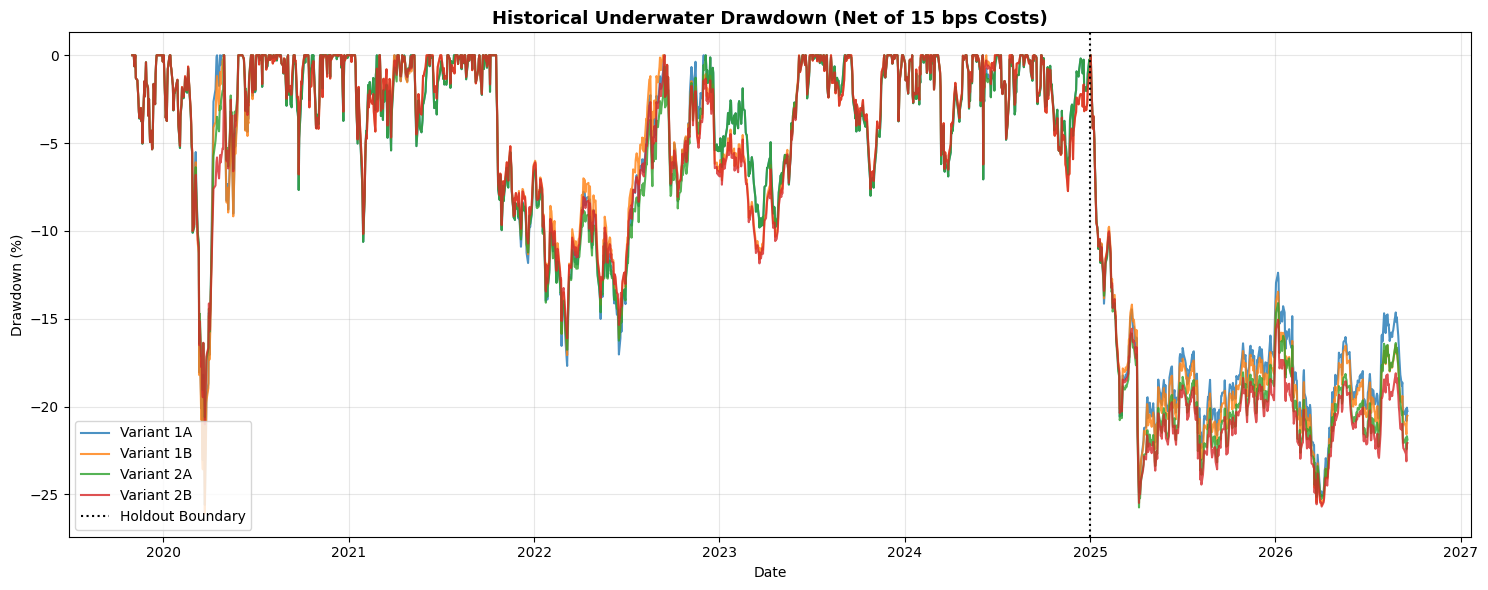

In [6]:
# Underwater Drawdown Comparison
plt.figure(figsize=(15, 6))
for v in VARIANTS:
    df = simulations[v]
    cum_nav = df["net_nav"]
    peaks = np.maximum.accumulate(cum_nav)
    drawdowns = (cum_nav - peaks) / peaks * 100.0
    plt.plot(df.index, drawdowns, label=f"Variant {v}", color=colors[v], alpha=0.8)

plt.axvline(pd.Timestamp("2024-12-31"), color="black", linestyle=":", label="Holdout Boundary")
plt.title("Historical Underwater Drawdown (Net of 15 bps Costs)", fontsize=13, fontweight="bold")
plt.ylabel("Drawdown (%)")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.show()

## 6. Realized Weights, Drift Dynamics and Turnover Analysis

Examine portfolio holdings across time. Under Template A, the strategy remains 100% invested in equities. Under Template B, defensive cash allocations expand up to 40% in crisis regimes (Regime 3).

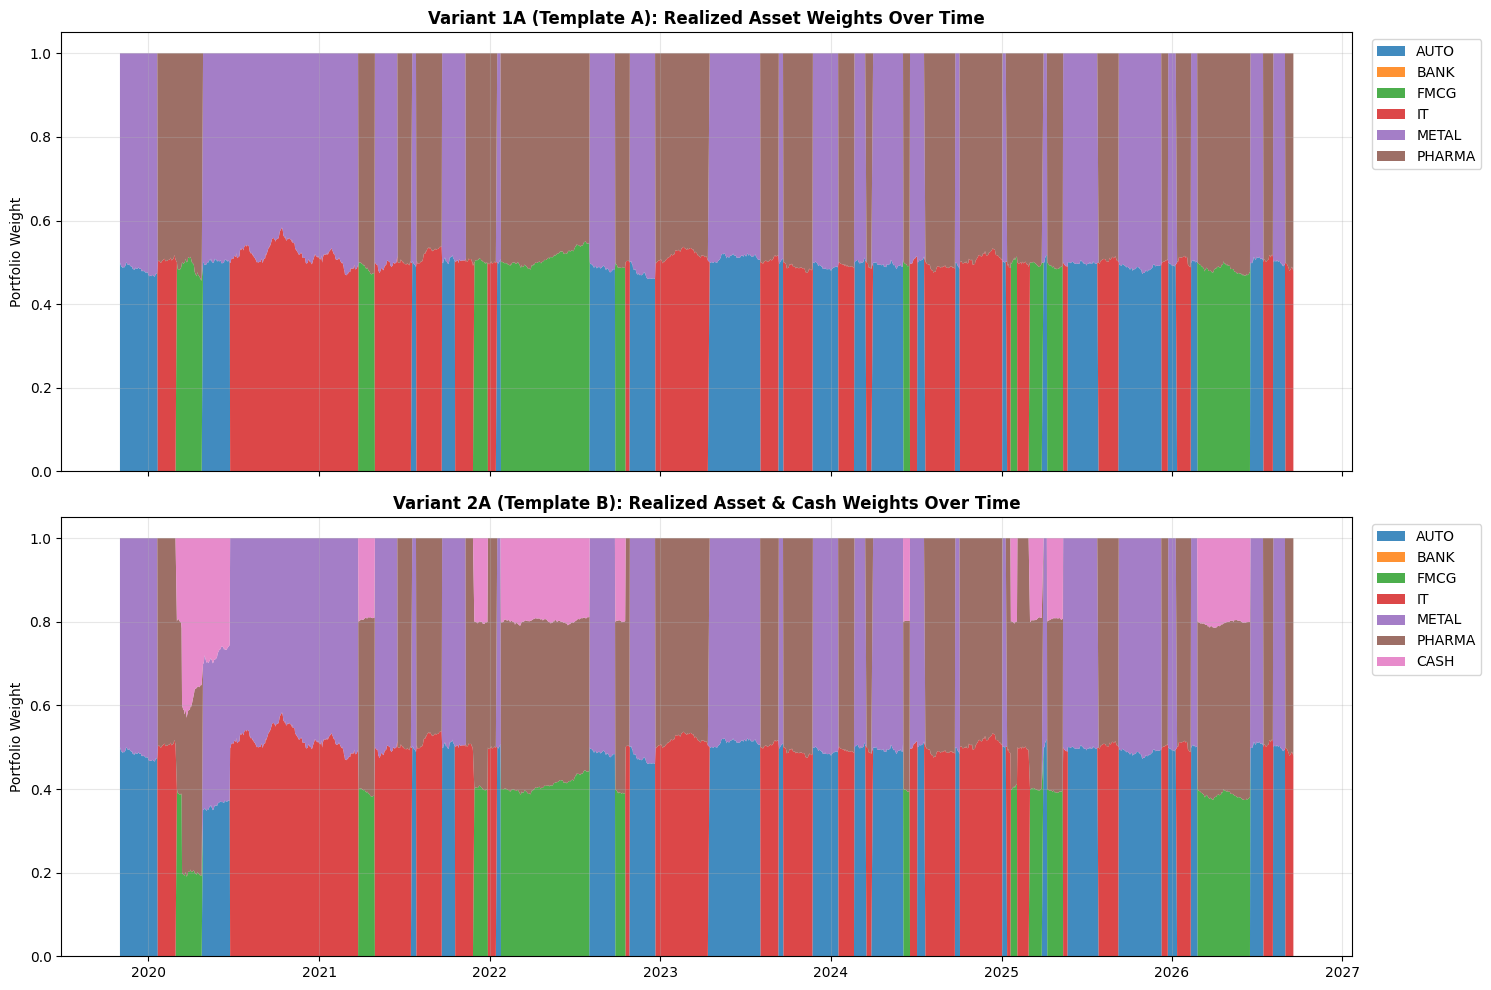

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# Stacked area chart for Variant 1A
df_1a = simulations["1A"]
w_cols_equity = [f"w_post_{s}" for s in SECTOR_NAMES]
ax1.stackplot(df_1a.index, [df_1a[col] for col in w_cols_equity], labels=SECTOR_NAMES, alpha=0.85)
ax1.set_title("Variant 1A (Template A): Realized Asset Weights Over Time", fontsize=12, fontweight="bold")
ax1.set_ylabel("Portfolio Weight")
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax1.grid(True, alpha=0.3)

# Stacked area chart for Variant 2A (with Cash)
df_2a = simulations["2A"]
w_cols_all = [f"w_post_{s}" for s in SECTOR_NAMES] + ["w_post_CASH"]
labels_all = SECTOR_NAMES + ["CASH"]
ax2.stackplot(df_2a.index, [df_2a[col] for col in w_cols_all], labels=labels_all, alpha=0.85)
ax2.set_title("Variant 2A (Template B): Realized Asset & Cash Weights Over Time", fontsize=12, fontweight="bold")
ax2.set_ylabel("Portfolio Weight")
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Actual vs Nominal Turnover Comparison
rebal_df = simulations["1A"][simulations["1A"]["rebalance_executed"]]
print(f"Variant 1A Rebalance Sessions: {len(rebal_df)}")
print(f"- Average nominal turnover: {rebal_df['nominal_turnover'].mean():.4f}")
print(f"- Average actual turnover (drift-adjusted): {rebal_df['actual_turnover'].mean():.4f}")
print(f"- Cumulative nominal turnover: {rebal_df['nominal_turnover'].sum():.4f}")
print(f"- Cumulative actual turnover: {rebal_df['actual_turnover'].sum():.4f}")

Variant 1A Rebalance Sessions: 58
- Average nominal turnover: 0.8707
- Average actual turnover (drift-adjusted): 0.8717
- Cumulative nominal turnover: 50.5000
- Cumulative actual turnover: 50.5609


## 7. Transaction Cost Analysis and CAGR Drag Quantification

Quantify the annual performance impact of the 15 bps one-way transaction fee.  
$\text{CAGR Drag} = \text{CAGR}_{\text{gross}} - \text{CAGR}_{\text{net}}$.

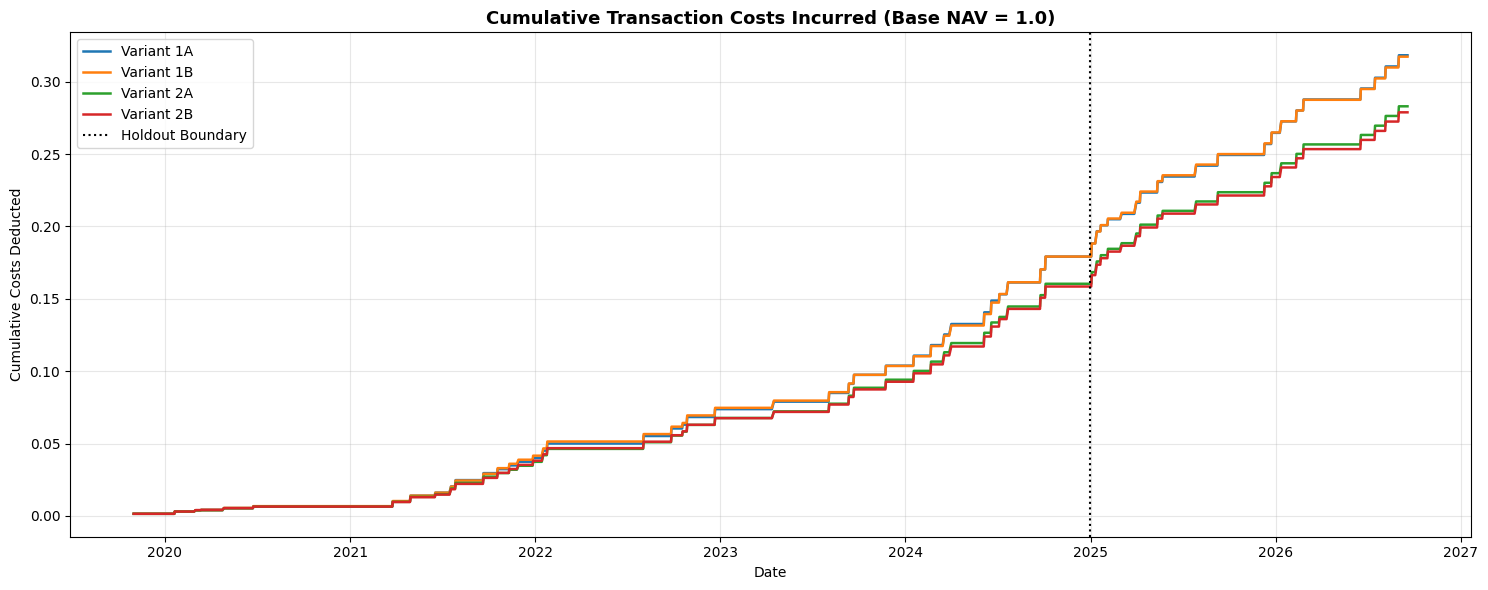

In [9]:
plt.figure(figsize=(15, 6))
for v in VARIANTS:
    df = simulations[v]
    cum_tc_nav = df["transaction_cost"].cumsum()
    plt.plot(df.index, cum_tc_nav, label=f"Variant {v}", color=colors[v], linewidth=1.8)

plt.axvline(pd.Timestamp("2024-12-31"), color="black", linestyle=":", label="Holdout Boundary")
plt.title("Cumulative Transaction Costs Incurred (Base NAV = 1.0)", fontsize=13, fontweight="bold")
plt.ylabel("Cumulative Costs Deducted")
plt.xlabel("Date")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

## 8. In-Sample (Train) vs Out-of-Sample (Holdout) Performance

Compile quantitative performance, risk, and turnover metrics across all 4 strategy variants for:
1. **Training Period** (1,264 return intervals, `2019-10-31` to `2024-12-31`)
2. **Holdout Period** (422 return intervals, `2025-01-02` to `2026-09-18`)
3. **Full Timeline** (1,686 return intervals, `2019-10-31` to `2026-09-18`)

In [10]:
metrics_table = generate_metrics_table(simulations, validate_counts=True)
display_cols = [
    "variant", "period", "return_intervals", "total_return_net_pct", "cagr_net_pct",
    "cagr_drag_pct", "ann_volatility_pct", "sharpe_ratio", "sortino_ratio",
    "max_drawdown_pct", "rebalances_executed", "ann_actual_turnover",
]
print("Performance Metrics Summary Table:")
print(metrics_table[display_cols].to_string(index=False))

Performance Metrics Summary Table:
variant  period  return_intervals  total_return_net_pct  cagr_net_pct  cagr_drag_pct  ann_volatility_pct  sharpe_ratio  sortino_ratio  max_drawdown_pct  rebalances_executed  ann_actual_turnover
     1A   train              1264            508.090581     43.316922       1.402937           20.441475      1.864307       2.742292        -25.597178                   38             6.489767
     1A holdout               422            -19.075868    -11.873156       1.434153           15.428144     -0.741591      -0.946177        -25.108817                   20            10.754204
     1A    full              1686            392.092022     26.892960       1.447627           19.352142      1.328372       1.908757        -25.597178                   58             7.557141
     1B   train              1264            502.445075     43.050662       1.437489           20.086581      1.884333       2.794062        -26.103327                   38             6.66

## 9. Exact Additive Return Attribution Reconciliation

Every daily return is decomposed into exact component contributions:  
$$R_{\text{net}, t} = \sum_{i \in \text{Assets}} (w_{i, t}^{\text{hold}} \cdot r_{i, t}) + C_{\text{cost}, t}$$
where $C_{\text{cost}, t} = R_{\text{net}, t} - R_{\text{gross}, t}$.  
The sum of asset contributions plus cost drag equals net return with zero mathematical approximation.

In [11]:
for v in VARIANTS:
    attr_df = compute_attribution(simulations[v])
    print(f"=== Sector Attribution: Variant {v} ===")
    print(attr_df[["period", "contrib_NIFTY50_pct", "contrib_AUTO_pct", "contrib_BANK_pct",
                   "contrib_FMCG_pct", "contrib_IT_pct", "contrib_METAL_pct", "contrib_PHARMA_pct",
                   "contrib_CASH_pct", "contrib_cost_pct", "reconciled_net_pct", "actual_net_sum_pct"]].to_string(index=False))
    max_err = np.abs(attr_df["reconciled_net_pct"] - attr_df["actual_net_sum_pct"]).max()
    print(f"Maximum Attribution Error: {max_err:.2e}\n")

=== Sector Attribution: Variant 1A ===
 period  contrib_NIFTY50_pct  contrib_AUTO_pct  contrib_BANK_pct  contrib_FMCG_pct  contrib_IT_pct  contrib_METAL_pct  contrib_PHARMA_pct  contrib_CASH_pct  contrib_cost_pct  reconciled_net_pct  actual_net_sum_pct
  train             0.110709         29.308769               0.0          8.288416       48.827147          74.591963           34.913299               0.0         -4.889496          191.150806          191.150806
holdout             0.000000         -6.122133               0.0          2.610336      -10.994259          -4.658478            2.701082               0.0         -2.696296          -19.159749          -19.159749
   full             0.110709         23.186635               0.0         10.898751       37.832888          69.933484           37.614382               0.0         -7.585793          171.991057          171.991057
Maximum Attribution Error: 2.84e-14

=== Sector Attribution: Variant 1B ===
 period  contrib_NIFTY50_pct 

## 10. Backtest Engine Verification and Parquet Persistence

Persist authoritative daily simulation records in Apache Parquet format and verify bit-level round-trip parity.

In [12]:
saved_paths = save_simulation_parquet(simulations)
audit_results = reload_and_verify_parquet(saved_paths, original_simulations=simulations)

print("Apache Parquet Audit & Parity Verification:")
for v, a in audit_results.items():
    print(f"Variant {v}:")
    print(f"  - File: {a['path']}")
    print(f"  - Size: {a['size_bytes']:,} bytes")
    print(f"  - Rows: {a['rows']}")
    print(f"  - Columns: {a['columns']}")
    print(f"  - Train intervals: {a['train_intervals']}")
    print(f"  - Holdout intervals: {a['holdout_intervals']}")
    print(f"  - Numerical parity confirmed: {a['parity_verified']}")
print("\nPhase 10.3 Portfolio Backtesting Engine successfully verified and persisted.")

Apache Parquet Audit & Parity Verification:
Variant 1A:
  - File: C:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery\results\portfolio_backtest\daily_simulation_1A.parquet
  - Size: 451,003 bytes
  - Rows: 1686
  - Columns: 70
  - Train intervals: 1264
  - Holdout intervals: 422
  - Numerical parity confirmed: True
Variant 1B:
  - File: C:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery\results\portfolio_backtest\daily_simulation_1B.parquet
  - Size: 454,105 bytes
  - Rows: 1686
  - Columns: 70
  - Train intervals: 1264
  - Holdout intervals: 422
  - Numerical parity confirmed: True
Variant 2A:
  - File: C:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery\results\portfolio_backtest\daily_simulation_2A.parquet
  - Size: 462,297 bytes
  - Rows: 1686
  - Columns: 70
  - Train intervals: 1264
  - Holdout intervals: 422
  - Numerical parity confirmed: True
Variant 2B:
  - File: C:\Users\vighn\OneDrive\Desktop\sector rotation regime discovery\results\